# 2. CNN inversion with EEI at four angles (seed 0)

This notebook reproduces the CNN result of the manuscript: the training set (100,000
pseudo-wells), the regression network (Vp, Vs, ρ, porosity, Vshale), the facies classification
network, their application to the field line, and Figures 9–15 and the CNN columns of Tables 3, 4
and 6.

The input is the EEI at χ = −60°, −7.5°, 25° and 45°, treated as a one-channel image of 4 angles
by 192 time samples. Both networks have the architecture of manuscript Figure 9 and are trained
with seed 0.

| | regression network | classification network |
|---|---|---|
| output | Vp, Vs, ρ, φ, Vshale at every 1 ms sample | probabilities of shale, silt, sand, calcareous sand |
| loss | mean square error of the standardised properties (eq. 13) | cross-entropy (eq. 14) |
| training | 150 epochs, batch 32, Adam with one-cycle schedule, max. learning rate 10⁻³, dropout 0.3 | 60 epochs, batch 256, time-stretch, gain and noise augmentation |
| field application | mean of 100 MC Dropout passes | mean of 50 MC Dropout passes |

The 100,000 pseudo-wells are split by pseudo-well into 80% training, 10% validation and 10% test.

**Run time:** about 50 minutes on one NVIDIA H100 GPU (the CNN also runs on a CPU, but slowly).
CNN training on a GPU is not bit-reproducible, so the numbers change slightly from run to run.

**Outputs:** `Notebooks/outputs/CNN/training_data/`, `regression_s0/` (with `field/` SEG-Y and
`figures/`), `facies_s0/`.

In [1]:
%matplotlib inline
import json, shutil, time
import numpy as np
from IPython.display import Markdown, display
from nb_utils import *

environment()

SEED = 0
REG = CNN_OUT / f"regression_s{SEED}"
FAC = CNN_OUT / f"facies_s{SEED}"
times = {}

Python 3.12.0, numpy 2.2.6


PyTorch 2.8.0+cu128, GPU: NVIDIA H100 80GB HBM3
CPU cores: 16
Package root: Stochastic_Inv_Code_Release/
Well 9P logs: not distributed (blind-well comparison skipped)


## 2.1 Training set: 100,000 pseudo-wells

The pseudo-wells are drawn from the same prior as ODiSI (`CNN_libs/make_datamat.py`). For each
pseudo-well we store the five properties and the facies on the 1 ms grid and the synthetic EEI
at the four angles, band-passed 3–60 Hz. The same random seed always gives the same pseudo-wells.

In [2]:
if not (TRAIN_DIR / "eei.npy").exists():
    times["generate 100,000 pseudo-wells"] = run("make_datamat.py", "--outdir", TRAIN_DIR, "--n", "100000",
                                                 "--format", "npy", log=CNN_OUT / "training_data.log")
else:
    print("training set exists:", TRAIN_DIR.relative_to(ROOT))
print({f: np.load(TRAIN_DIR / f"{f}.npy", mmap_mode="r").shape for f in ("eei", "props", "facies")})

$ python CNN_libs/make_datamat.py --outdir Notebooks/outputs/CNN/training_data --n 100000 --format npy


  thickest trace 18: layers [48, 80, 56] ms, TWT 2.828-3.011 s
  facies 1 s
  rock physics 7 s
  EEI 11 s
  wrote Notebooks/outputs/CNN/training_data/ (npy) in 15 s
[16 s, full log: Notebooks/outputs/CNN/training_data.log]
{'eei': (100000, 4, 192), 'props': (100000, 5, 192), 'facies': (100000, 192)}


Three examples of the training pseudo-wells and their synthetic EEI:

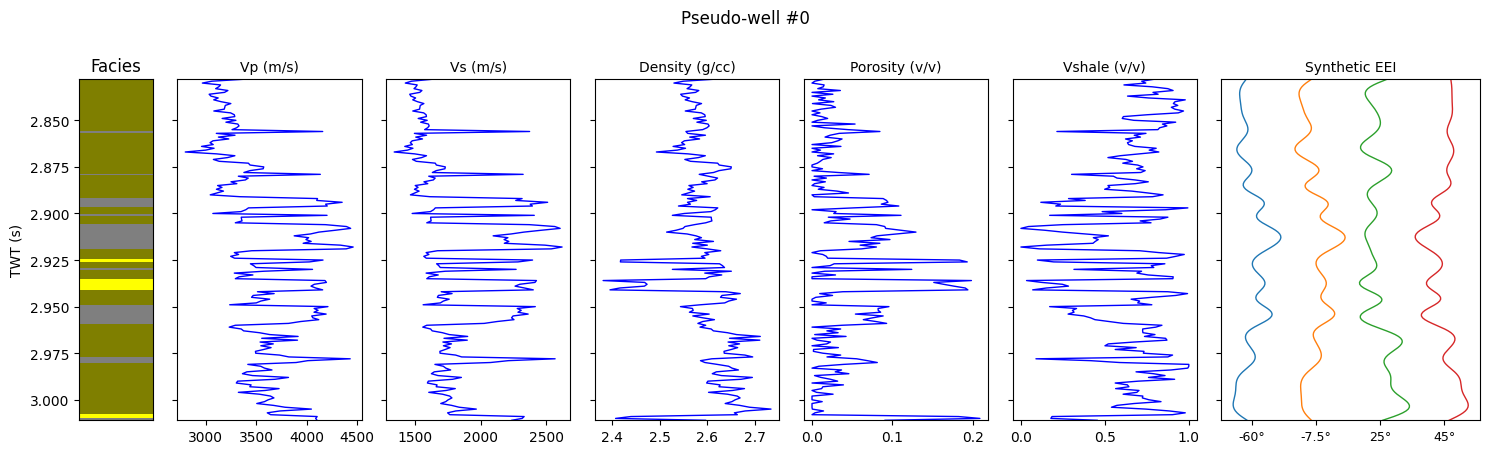

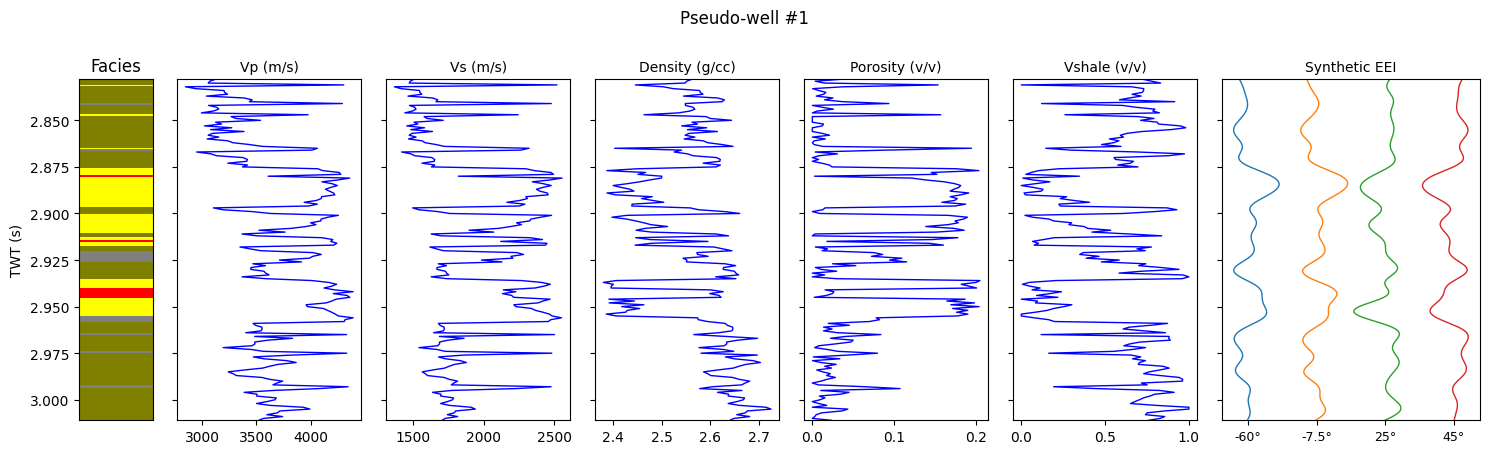

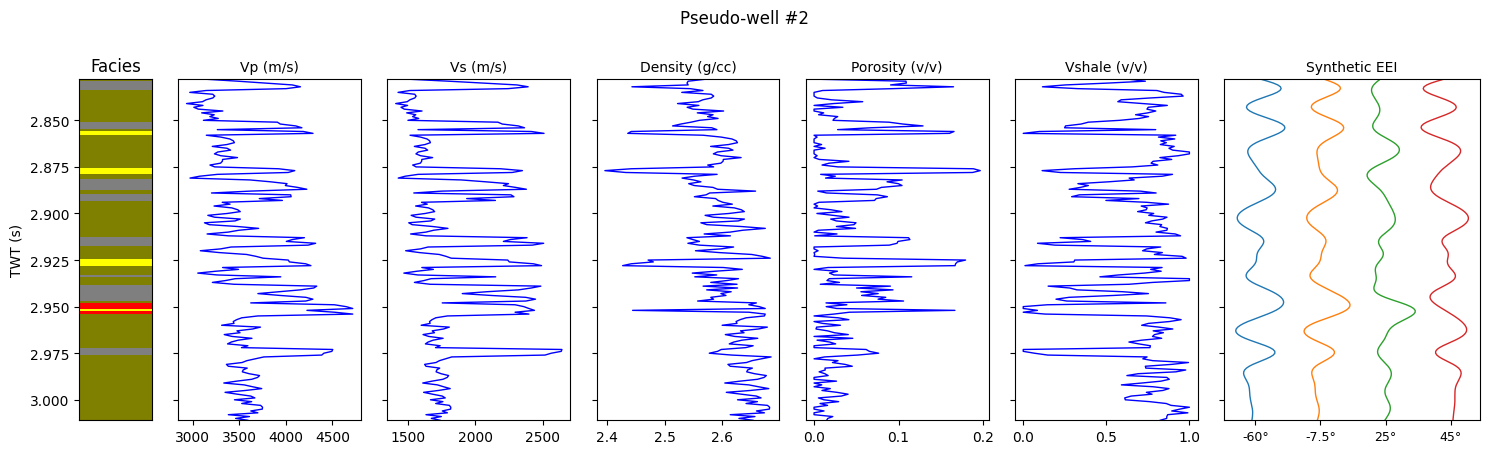

Facies fractions over the training set: shale 71.7%, silt 11.4%, sand 14.4%, calcareous sand 2.5%


In [3]:
plot_pseudowells(TRAIN_DIR, idx=(0, 1, 2))

## 2.2 Regression network

Training on the 80,000 training pseudo-wells; the weights of the epoch with the lowest
validation loss are kept. The validation loss is below the training loss because dropout is
active only when the training loss is computed.

$ python CNN_libs/train_cnn.py --train-dir Notebooks/outputs/CNN/training_data --outdir Notebooks/outputs/CNN/regression_s0 --seed 0 --arch keras --epochs 150 --batch 32 --lr 1e-3 --weight-decay 0 --dropout 0.3 --reg-loss mse --cls-weight 0 --calibration none --gain-jitter 0 --mc-test 0


  ...
  epoch 148  train 0.4012 (reg 0.4012, CE 1.3863)  val 0.3427 (reg 0.3427, CE 1.3863)  1091 s
  epoch 149  train 0.4010 (reg 0.4010, CE 1.3863)  val 0.3425 (reg 0.3425, CE 1.3863)  1098 s
  epoch 150  train 0.4010 (reg 0.4010, CE 1.3863)  val 0.3424 (reg 0.3424, CE 1.3863)  1106 s
  median correlation per pseudo-well         vp      vs     rho    poro  vshale
  train                0.835   0.839   0.816   0.797   0.771   facies acc 0.717, macro-F1 0.209
  test                 0.835   0.839   0.817   0.796   0.768   facies acc 0.718, macro-F1 0.209
  test_noise_free      0.835   0.839   0.817   0.796   0.768   facies acc 0.718, macro-F1 0.209
  coverage of 50%/90% intervals, test: vp 0.00/0.00, vs 0.00/0.00, rho 0.00/0.00, poro 0.00/0.00, vshale 0.00/0.00
  coverage of 50%/90% intervals, test_noise_free: vp 0.00/0.00, vs 0.00/0.00, rho 0.00/0.00, poro 0.00/0.00, vshale 0.00/0.00
  saved model and QC figures to Notebooks/outputs/CNN/regression_s0/ (training 1106 s)
[1120 s, full lo

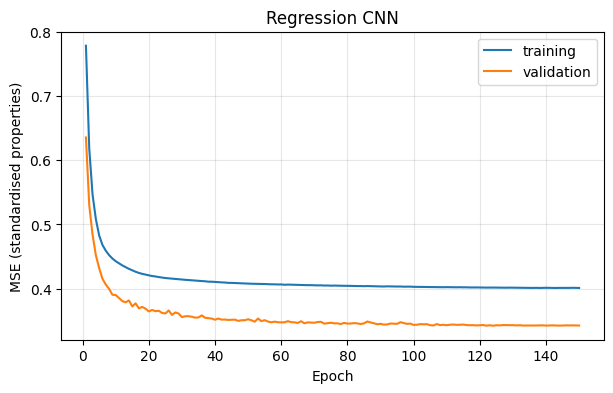

In [4]:
if not (REG / "model.pt").exists():
    times["train regression network"] = run("train_cnn.py", "--train-dir", TRAIN_DIR, "--outdir", REG,
                                            "--seed", SEED, *REG_ARGS, log=REG / "train.log", tail=10)
else:
    print("regression network exists:", REG.relative_to(ROOT))
plot_history(REG)

Median correlation coefficient between the predicted and true logs of the 10,000 test pseudo-wells:

In [5]:
r = test_correlations(REG)
table({"this run": r, "manuscript": dict(zip(PROPS, (0.84, 0.84, 0.82, 0.80, 0.77)))}, list(PROPS),
      fmt="{:.2f}", index_name="test pseudo-wells")

| test pseudo-wells | vp | vs | rho | poro | vshale |
|---|---|---|---|---|---|
| this run | 0.84 | 0.84 | 0.82 | 0.80 | 0.77 |
| manuscript | 0.84 | 0.84 | 0.82 | 0.80 | 0.77 |

## 2.3 Application to the field line

The field EEI at the four angles is computed from the AVO intercept and gradient, the window of
each trace is resampled onto the 184-sample training window, and each angle is standardised over
the line. The network is applied with 100 MC Dropout passes; the mean and the quantiles of the
passes are written as SEG-Y on the 1 ms grid of the ODiSI results.

In [6]:
times["apply regression network (283 traces, 100 passes)"] = run(
    "infer_cnn.py", "--run", REG, "--field-mode", "stretch", "--mc", "100", "--tag", f"cnn_s{SEED}",
    "--outdir", REG / "field", log=REG / "infer.log", tail=4)

$ python CNN_libs/infer_cnn.py --run Notebooks/outputs/CNN/regression_s0 --field-mode stretch --mc 100 --tag cnn_s0 --outdir Notebooks/outputs/CNN/regression_s0/field


  ...
  field EEI: 283 traces x 4 angles (-60..45 deg); calibration stretch (ODiSI window), per-angle standardisation: intercept gain 1.000, gradient gain 1.000
  inference: 100 MC-dropout passes in 0.37 s (input preparation 0.2 s)
  wrote SEG-Y and cnn_cnn_s0.npz to Notebooks/outputs/CNN/regression_s0/field/
  wrote sections_cnn_s0.png
[7 s, full log: Notebooks/outputs/CNN/regression_s0/infer.log]


## 2.4 Facies classification network

Same architecture, trained with the cross-entropy loss and with random time stretching, gains and
noise applied to the synthetic EEI. Because shale makes up about 72% of the samples, the facies
are assigned from weighted probabilities, with weights tuned on the validation pseudo-wells. The
script also applies the network to the field line (50 MC Dropout passes).

In [7]:
if not (FAC / "metrics.json").exists():
    times["train classification network + field line"] = run(
        "classify_facies.py", "--train-dir", TRAIN_DIR, "--outdir", FAC, "--tag", f"facies_s{SEED}",
        "--seed", SEED, "--arch", "keras", "--dropout", "0.3", "--lr", "1e-3", "--epochs", "60",
        "--batch", "256", "--weight-decay", "0", "--baseline-run", REG / "field",
        log=FAC / "train.log", tail=8)
else:
    print("classification network exists:", FAC.relative_to(ROOT))

$ python CNN_libs/classify_facies.py --train-dir Notebooks/outputs/CNN/training_data --outdir Notebooks/outputs/CNN/facies_s0 --tag facies_s0 --seed 0 --arch keras --dropout 0.3 --lr 1e-3 --epochs 60 --batch 256 --weight-decay 0 --baseline-run Notebooks/outputs/CNN/regression_s0/field


  ...
  arch keras, 0.37 M parameters, 60 epochs, 71 s; decision macro_f1 (weights 1.00, 1.26, 0.80, 2.24)
  | | accuracy | balanced acc. | macro-F1 | F1 shale | F1 silt | F1 sand | F1 calcareous sand |
  |---|---|---|---|---|---|---|---|
  | test pseudo-wells, clean, argmax | 0.871 | 0.624 | 0.659 | 0.94 | 0.62 | 0.76 | 0.32 |
  | test pseudo-wells, clean, tuned | 0.870 | 0.666 | 0.687 | 0.94 | 0.63 | 0.76 | 0.42 |
  | test pseudo-wells, augmented, argmax | 0.858 | 0.615 | 0.647 | 0.93 | 0.60 | 0.76 | 0.30 |
  | test pseudo-wells, augmented, tuned | 0.857 | 0.657 | 0.677 | 0.93 | 0.62 | 0.75 | 0.41 |
  wrote Notebooks/outputs/CNN/facies_s0/
[81 s, full log: Notebooks/outputs/CNN/facies_s0/train.log]


## 2.5 Figures of the manuscript

`make_paper_figures.py` draws the field sections and the Well 9P panel, and
`make_training_figures.py` the training curve, the pseudo-well examples, the correlation
distributions and the confusion matrices.

In [8]:
run("make_paper_figures.py", "--input-dir", REG / "field", "--tag", f"cnn_s{SEED}", "--run-name", f"CNN_s{SEED}",
    "--outdir", REG / "figures", "--facies-segy", FAC / f"facies_facies_s{SEED}.segy",
    "--formats", "png", "pdf", "--dpi", "120", log=REG / "figures" / "figures.log", tail=3)
run("make_training_figures.py", "--reg-run", REG, "--facies-run", FAC, "--train-dir", TRAIN_DIR,
    "--outdir", REG / "figures", "--formats", "png", "pdf", "--dpi", "120",
    log=REG / "figures" / "training_figures.log", tail=3)
FIG = REG / "figures"

$ python ODiSI_libs/make_paper_figures.py --input-dir Notebooks/outputs/CNN/regression_s0/field --tag cnn_s0 --run-name CNN_s0 --outdir Notebooks/outputs/CNN/regression_s0/figures --facies-segy Notebooks/outputs/CNN/facies_s0/facies_facies_s0.segy --formats png pdf --dpi 120


  ...
    wrote Cal_seismic_data_CNN_s0.png/pdf
    Data/well9p_data.mat not found — Figure 3 shows the inversion only, no well logs or correlations
    wrote Well_9p_elasto_petrophysics_CNN_s0.png/pdf
[5 s, full log: Notebooks/outputs/CNN/regression_s0/figures/figures.log]
$ python CNN_libs/make_training_figures.py --reg-run Notebooks/outputs/CNN/regression_s0 --facies-run Notebooks/outputs/CNN/facies_s0 --train-dir Notebooks/outputs/CNN/training_data --outdir Notebooks/outputs/CNN/regression_s0/figures --formats png pdf --dpi 120


  ...
  train (n=80,000, example #90602): median r vp 0.835 vs 0.839 rho 0.816 poro 0.797 vshale 0.769; facies accuracy 0.869, balanced 0.664, macro-F1 0.685, recall 0.96 0.61 0.71 0.38
  test  (n=10,000, example #82830): median r vp 0.835 vs 0.839 rho 0.817 poro 0.796 vshale 0.768; facies accuracy 0.870, balanced 0.666, macro-F1 0.687, recall 0.96 0.60 0.71 0.38
  wrote figures to Notebooks/outputs/CNN/regression_s0/figures/
[9 s, full log: Notebooks/outputs/CNN/regression_s0/figures/training_figures.log]


**Manuscript Figure 10**: training curve of the regression network.

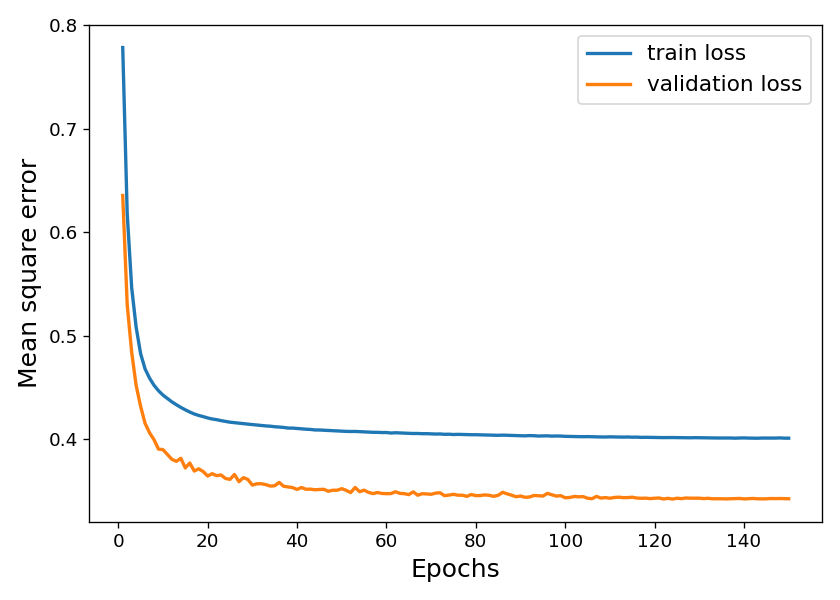

In [9]:
show(FIG / "training_curve.png", width=700)

**Manuscript Figure 11**: a typical (a) training and (b) test pseudo-well, true logs and prediction.

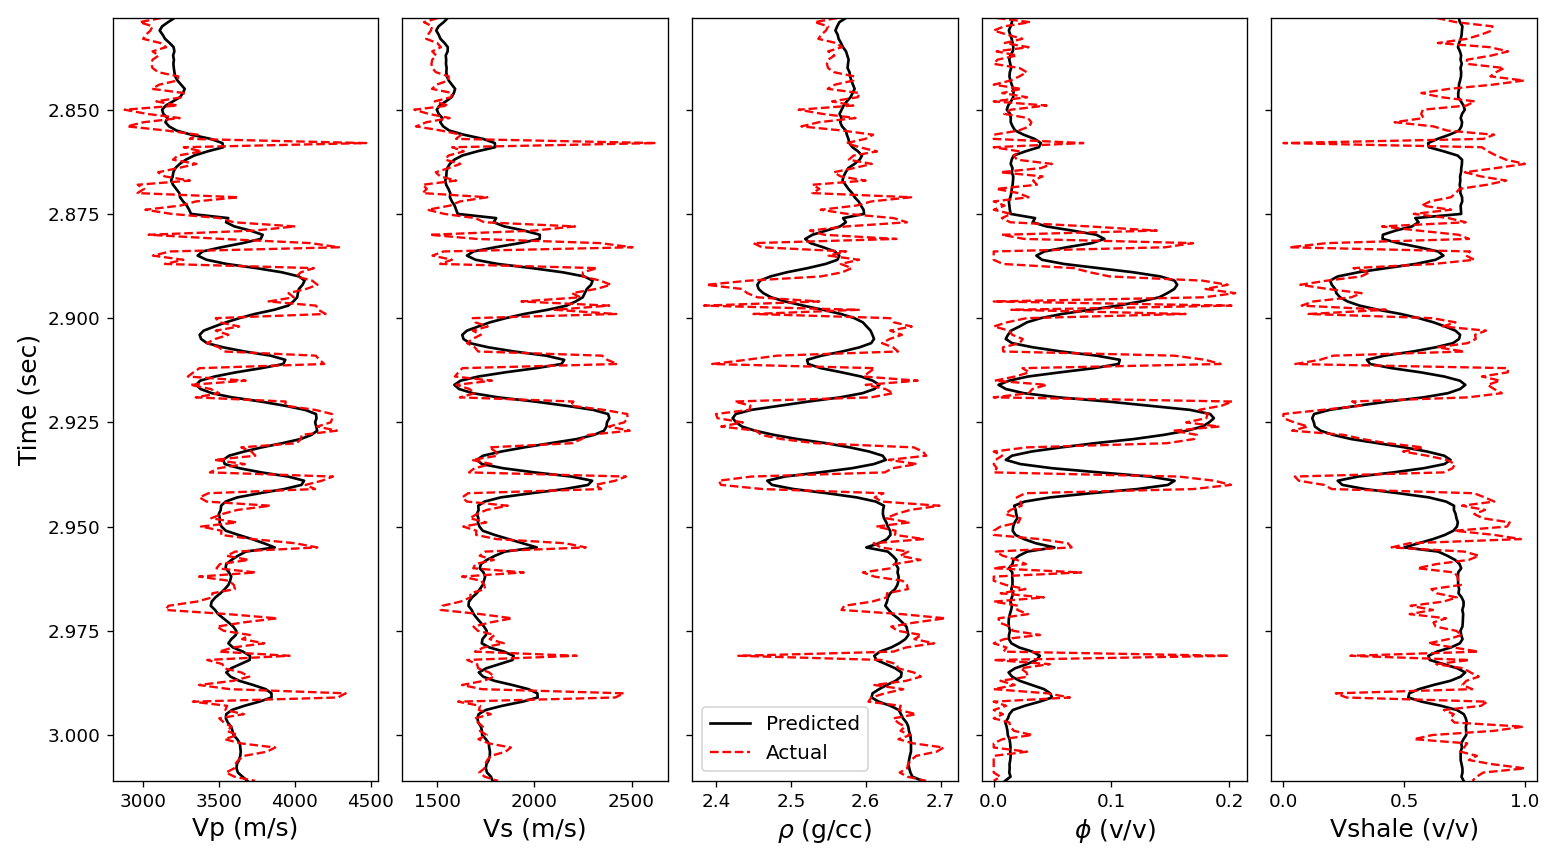

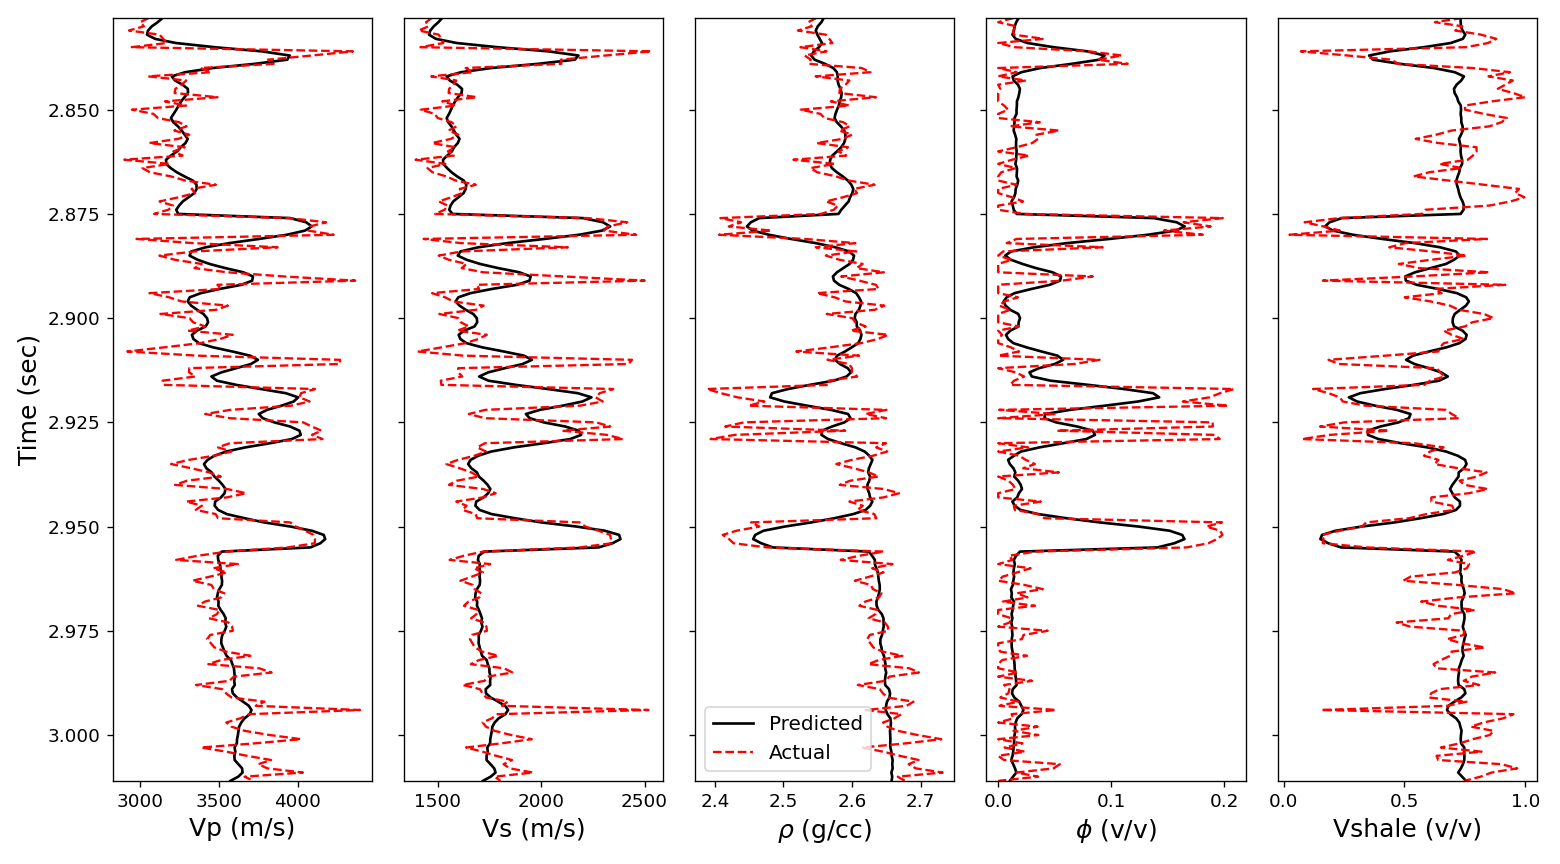

In [10]:
show(FIG / "training_result_elasto_petrophysics.png", FIG / "testing_result_elasto_petrophysics.png", width=850)

**Manuscript Figure 12**: correlation per pseudo-well, 80,000 training and 10,000 test pseudo-wells.

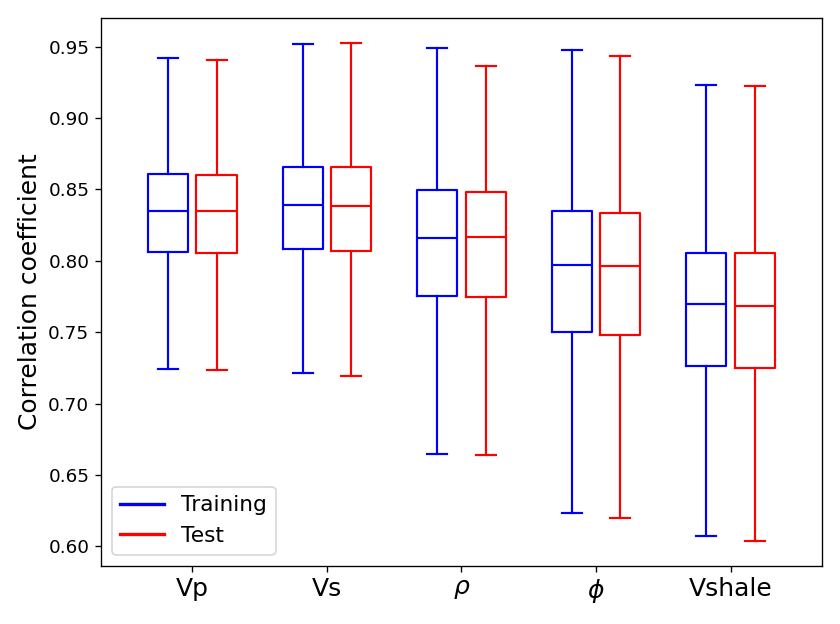

In [11]:
show(FIG / "correlation_elasto_petrophysics.png", width=850)

**Manuscript Figure 13**: confusion matrices of the facies network on the training and test pseudo-wells.

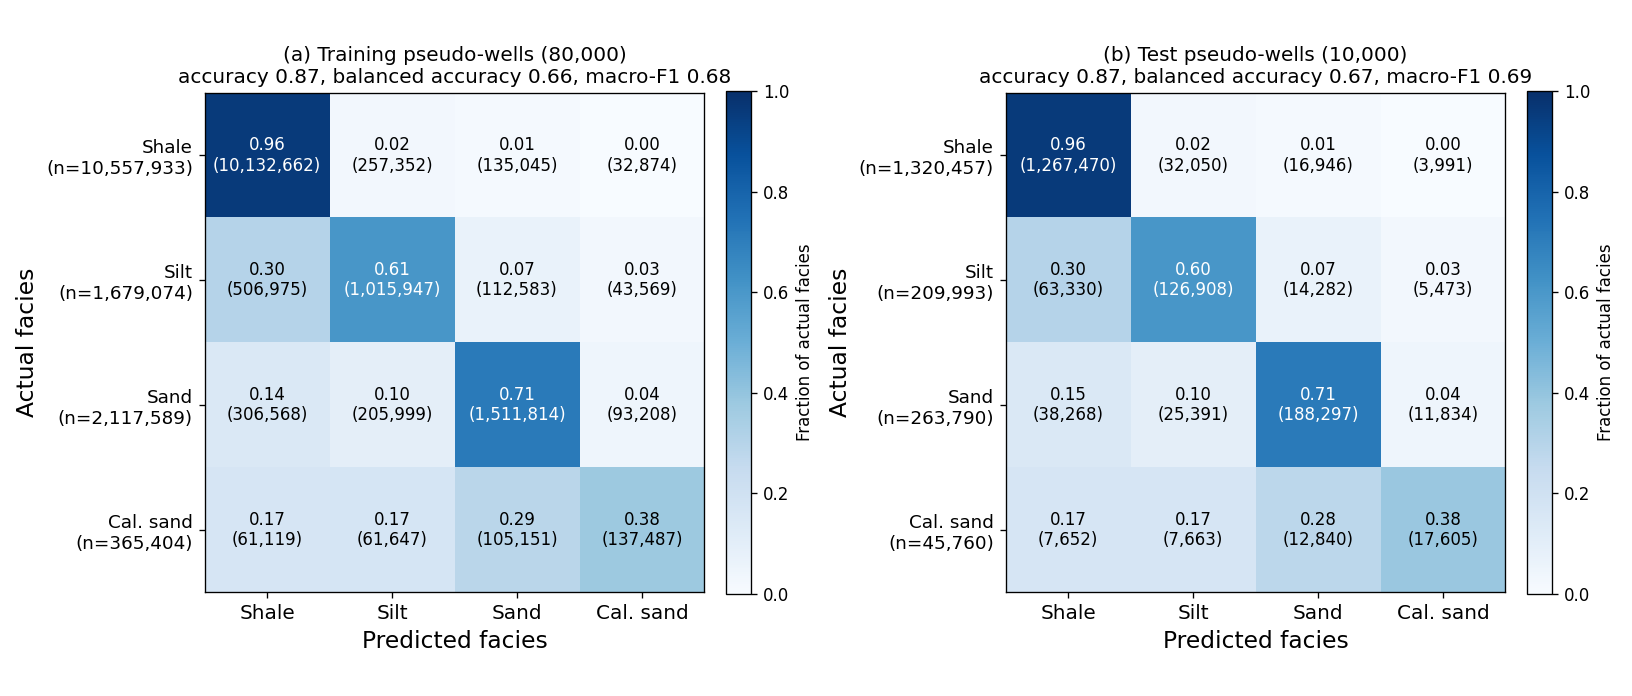

In [12]:
show(FIG / "facies_confusion.png", width=850)

**Manuscript Figure 14**: CNN sections of the field line (regression mean and classified facies).

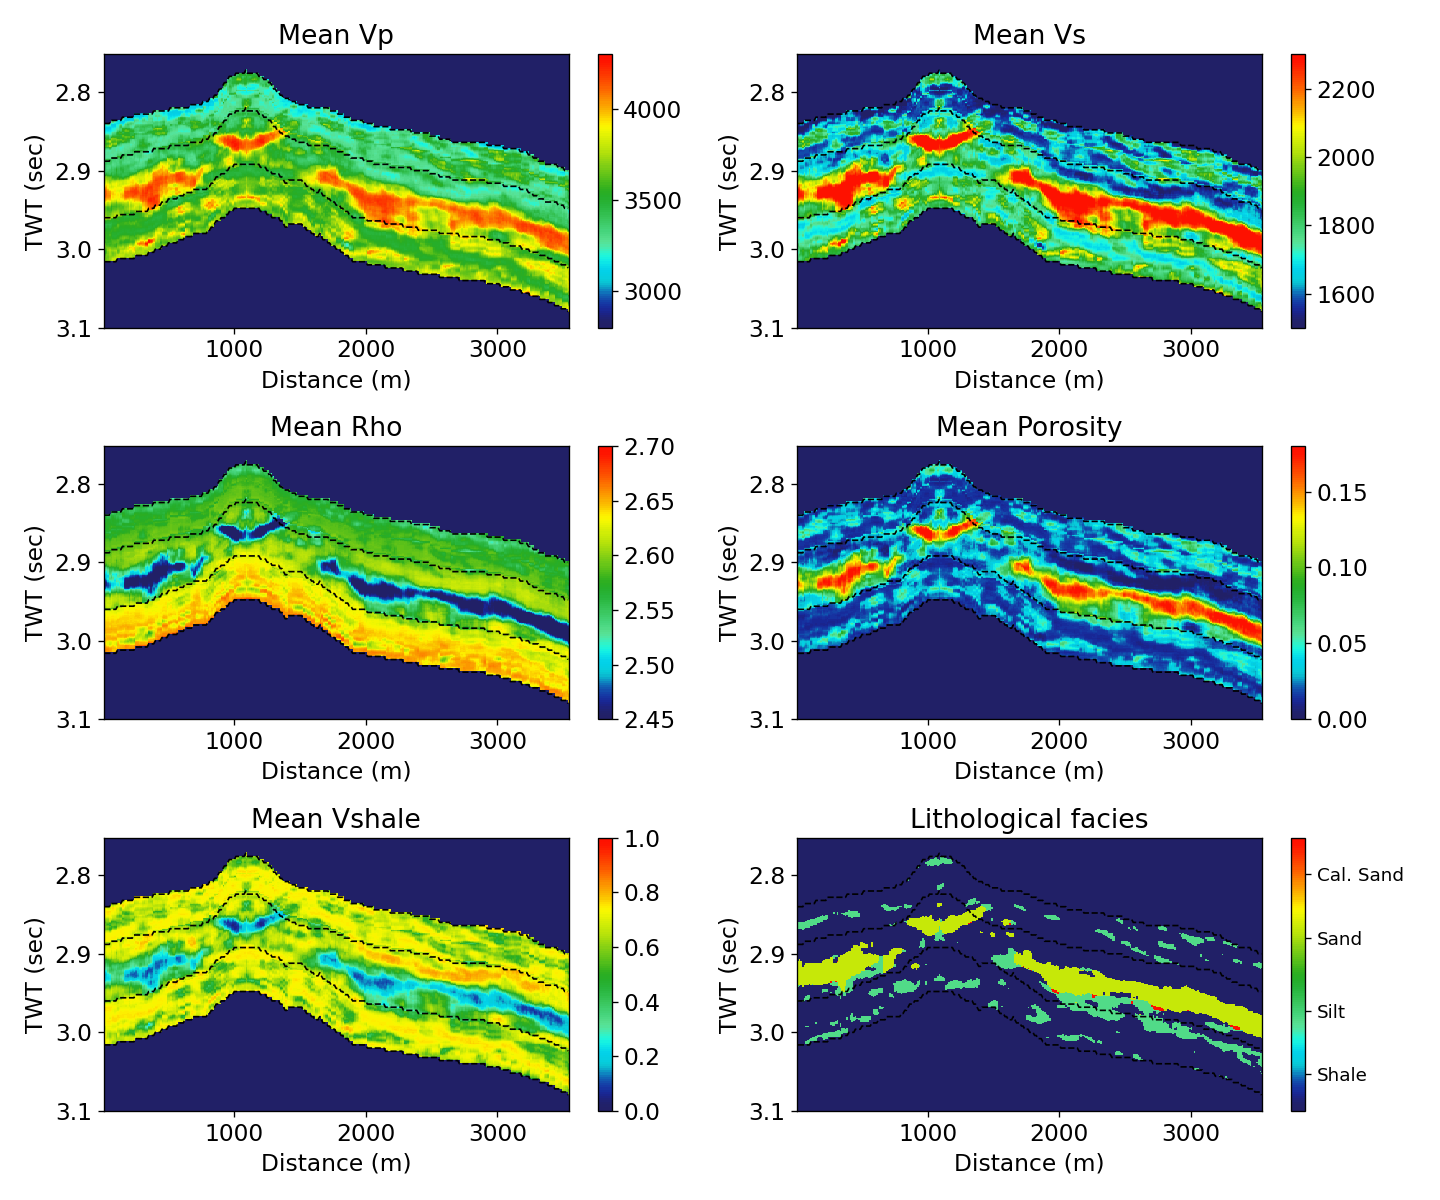

In [13]:
show(first(FIG, "Stochastic_inversion_*CNN_s0*.png"))

**Manuscript Figure 15**: the CNN result along the path of Well 9P, with the 25th and 75th
percentiles of the MC Dropout passes. Without the (proprietary) Well 9P logs, the panel shows the
inversion only.

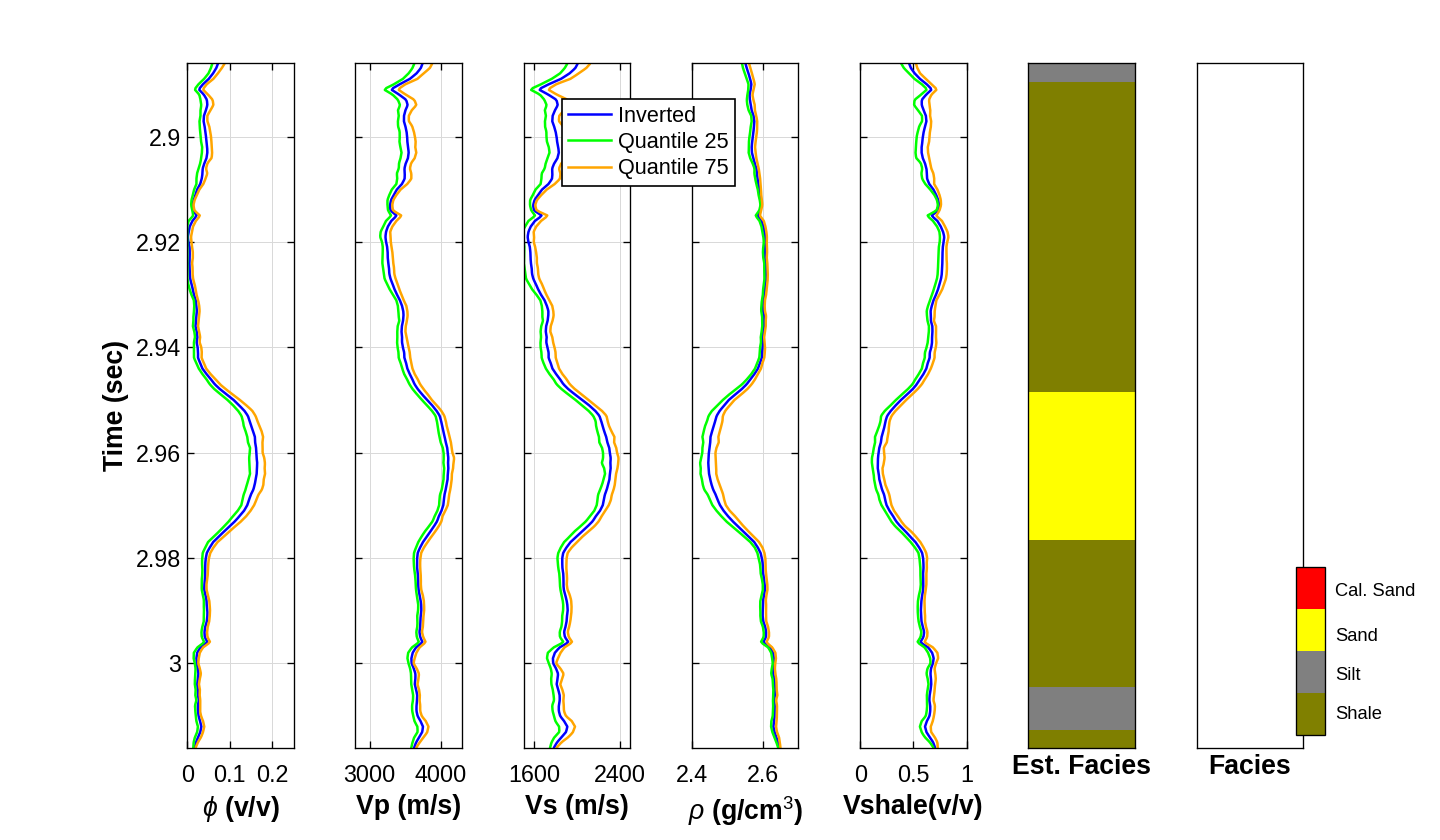

In [14]:
show(first(FIG, "Well_9p_elasto_petrophysics_*.png"), width=900)

## 2.6 Blind-well comparison and computing time

Correlation coefficients at Well 9P in the manuscript (Table 3, CNN):

| Vp | Vs | ρ | Vshale | φ | mean |
|---|---|---|---|---|---|
| 0.699 | 0.780 | 0.704 | 0.731 | 0.674 | 0.718 |

In [15]:
r = read_well_correlation(FIG / f"well_correlation_CNN_s{SEED}.txt")
if r:
    table({"CNN, this run": r}, list(PROPS))
else:
    print("Well 9P logs not available: blind-well correlations not computed.")

summary = json.loads((FIG / "training_figures_summary.json").read_text())
rows = {f"{s}, this run": {k: summary[s]["facies"][k] for k in ("accuracy", "balanced_accuracy", "macro_f1")}
        for s in ("train", "test")}
rows["test, manuscript"] = dict(accuracy=0.87, balanced_accuracy=0.66, macro_f1=0.69)
display(Markdown("Facies network on the pseudo-wells (Figure 13):"))
table(rows, ["accuracy", "balanced_accuracy", "macro_f1"], fmt="{:.2f}", index_name="pseudo-wells")

if times:
    table({k: {"time (s)": v} for k, v in times.items()}, ["time (s)"], fmt="{:.0f}", index_name="step")
    once = sum(v for k, v in times.items() if not k.startswith("apply"))
    apply = sum(v for k, v in times.items() if k.startswith("apply"))
    print(f"one-time cost (training set and training): {once:.0f} s; field line: {apply:.1f} s "
          f"({1000 * apply / 283:.0f} ms per trace, including start-up of the script)")

Well 9P logs not available: blind-well correlations not computed.


Facies network on the pseudo-wells (Figure 13):

| pseudo-wells | accuracy | balanced_accuracy | macro_f1 |
|---|---|---|---|
| train, this run | 0.87 | 0.66 | 0.68 |
| test, this run | 0.87 | 0.67 | 0.69 |
| test, manuscript | 0.87 | 0.66 | 0.69 |

| step | time (s) |
|---|---|
| generate 100,000 pseudo-wells | 16 |
| train regression network | 1120 |
| apply regression network (283 traces, 100 passes) | 7 |
| train classification network + field line | 81 |

one-time cost (training set and training): 1217 s; field line: 6.9 s (24 ms per trace, including start-up of the script)
